<a href="https://colab.research.google.com/github/pranita2113/MachineLearning-Project_EE/blob/main/Project_code_of_ML_EE514.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

“World Population Growth Analysis and Visualization”

Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import  train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


In [ ]:
import pandas as pd
df=pd.read_csv('/content/countries_population.csv')

Data Collection


In [ ]:
df.head()

,Country,ISO3,Year,Population,Population Growth,Growth Rate (%),Decade
0,Afghanistan,AFG,1960,8996973,NaN,NaN,1960s
1,Afghanistan,AFG,1961,9169410,172437.0,1.916611,1960s
2,Afghanistan,AFG,1962,9351441,182031.0,1.985199,1960s
3,Afghanistan,AFG,1963,9543205,191764.0,2.050636,1960s
4,Afghanistan,AFG,1964,9744781,201576.0,2.112246,1960s


In [ ]:
df.shape

(15409, 7)

In [ ]:
df.columns

Index(['Country', 'ISO3', 'Year', 'Population', 'Population Growth',
       'Growth Rate (%)', 'Decade'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15409 entries, 0 to 15408
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            15409 non-null  object 
 1   ISO3               15409 non-null  object 
 2   Year               15409 non-null  int64  
 3   Population         15409 non-null  int64  
 4   Population Growth  15146 non-null  float64
 5   Growth Rate (%)    15146 non-null  float64
 6   Decade             15409 non-null  object 
dtypes: float64(2), int64(2), object(3)
memory usage: 842.8+ KB


Data Cleaning and Perprocessing

In [ ]:
df = df.drop_duplicates()

In [ ]:
df["Population"] = pd.to_numeric(
    df["Population"], errors="coerce"
)

In [ ]:
df = df.dropna(
    subset=["Country", "Year", "Population"]
)


In [ ]:
df = df[df["Population"] >= 0]

In [ ]:
df["Year"] = df["Year"].astype(int)

In [ ]:


print("Missing values:")
print(df.isnull().sum())

print("Cleaned dataset:")
print(df.head())

Missing values:
Country                0
ISO3                   0
Year                   0
Population             0
Population Growth    263
Growth Rate (%)      263
Decade                 0
dtype: int64
Cleaned dataset:
       Country ISO3  Year  Population  Population Growth  Growth Rate (%)  \
0  Afghanistan  AFG  1960     8996973                NaN              NaN   
1  Afghanistan  AFG  1961     9169410           172437.0         1.916611   
2  Afghanistan  AFG  1962     9351441           182031.0         1.985199   
3  Afghanistan  AFG  1963     9543205           191764.0         2.050636   
4  Afghanistan  AFG  1964     9744781           201576.0         2.112246   

  Decade  
0  1960s  
1  1960s  
2  1960s  
3  1960s  
4  1960s  


In [ ]:
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["Population"] = pd.to_numeric(df["Population"], errors="coerce")

df = df.drop_duplicates()
df = df.dropna(subset=["Country", "Year", "Population"])
df = df[df["Population"] >= 0]
df["Year"] = df["Year"].astype(int)


Exploratory Data Analysis

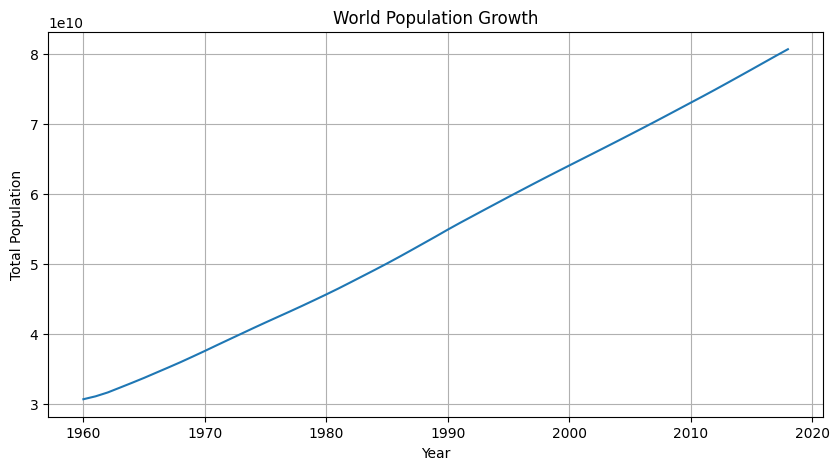

In [ ]:
population_year = df.groupby("Year")["Population"].sum()

plt.figure(figsize=(10, 5))
plt.plot(population_year.index, population_year.values)

plt.title("World Population Growth")
plt.xlabel("Year")
plt.ylabel("Total Population")
plt.grid(True)
plt.show()

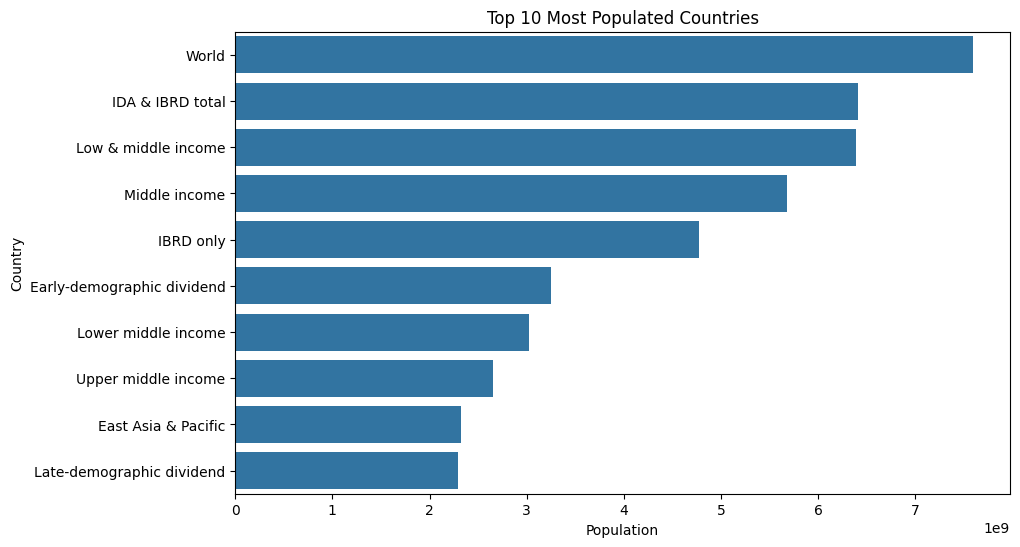

In [ ]:
latest_year = df["Year"].max()

latest_data = df[df["Year"] == latest_year]

top10 = latest_data.nlargest(10, "Population")

plt.figure(figsize=(10, 6))
sns.barplot(data=top10, x="Population", y="Country")

plt.title("Top 10 Most Populated Countries")
plt.xlabel("Population")
plt.ylabel("Country")
plt.show()

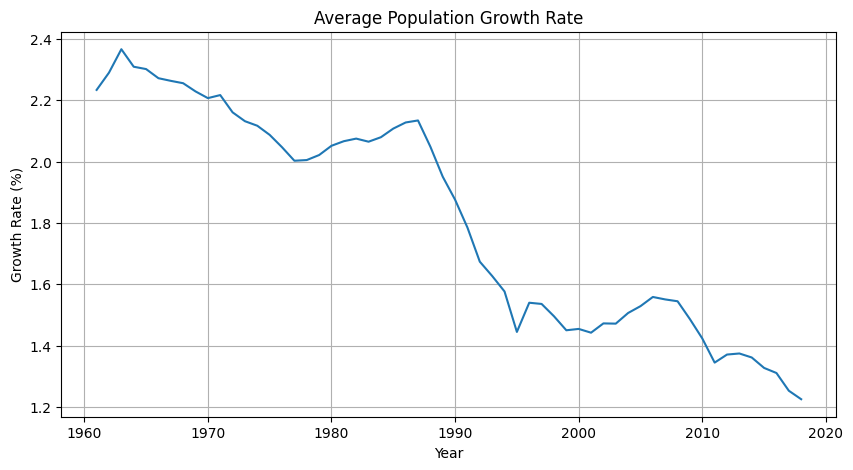

In [ ]:
growth = df.groupby("Year")["Growth Rate (%)"].mean()

plt.figure(figsize=(10, 5))
plt.plot(growth.index, growth.values)

plt.title("Average Population Growth Rate")
plt.xlabel("Year")
plt.ylabel("Growth Rate (%)")
plt.grid(True)
plt.show()

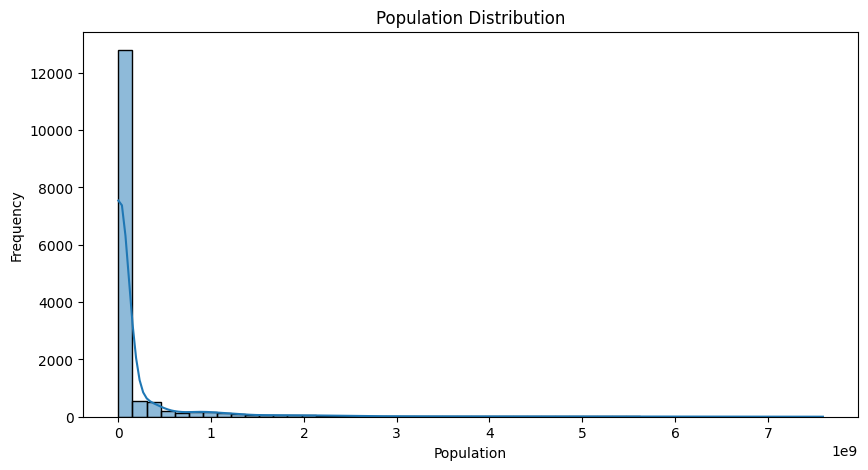

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Population"], bins=50, kde=True)

plt.title("Population Distribution")
plt.xlabel("Population")
plt.ylabel("Frequency")
plt.show()

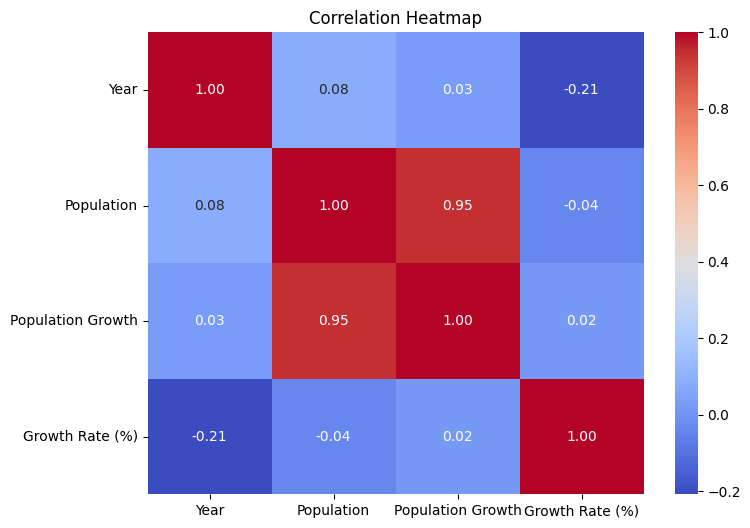

In [ ]:
numeric_data = df.select_dtypes(include=np.number)

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

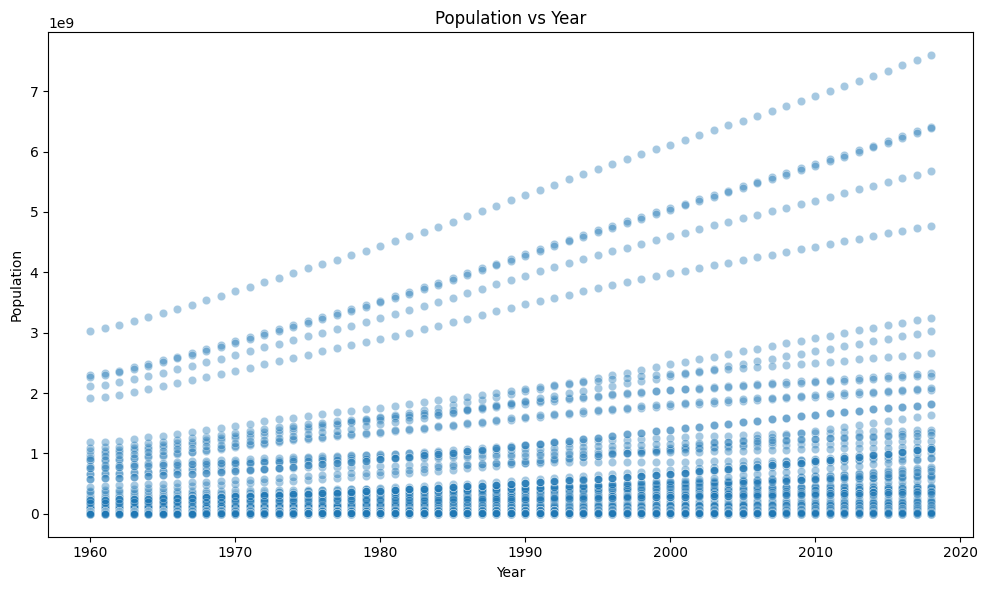

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Year",
    y="Population",
    alpha=0.4
)

plt.title("Population vs Year")
plt.xlabel("Year")
plt.ylabel("Population")
plt.tight_layout()
plt.show()

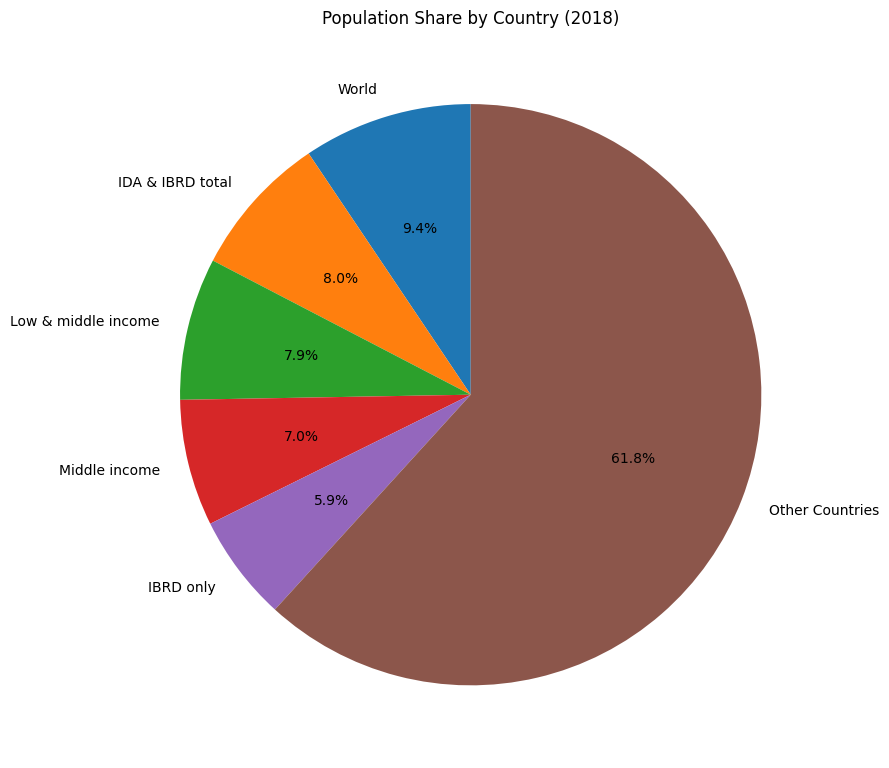

In [ ]:
latest_year = df["Year"].max()

latest_data = df[df["Year"] == latest_year]

top5 = latest_data.nlargest(5, "Population")

others = latest_data[
    ~latest_data["Country"].isin(top5["Country"])
]["Population"].sum()

labels = list(top5["Country"]) + ["Other Countries"]

values = list(top5["Population"]) + [others]

plt.figure(figsize=(9, 9))

plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(f"Population Share by Country ({latest_year})")
plt.tight_layout()
plt.show()

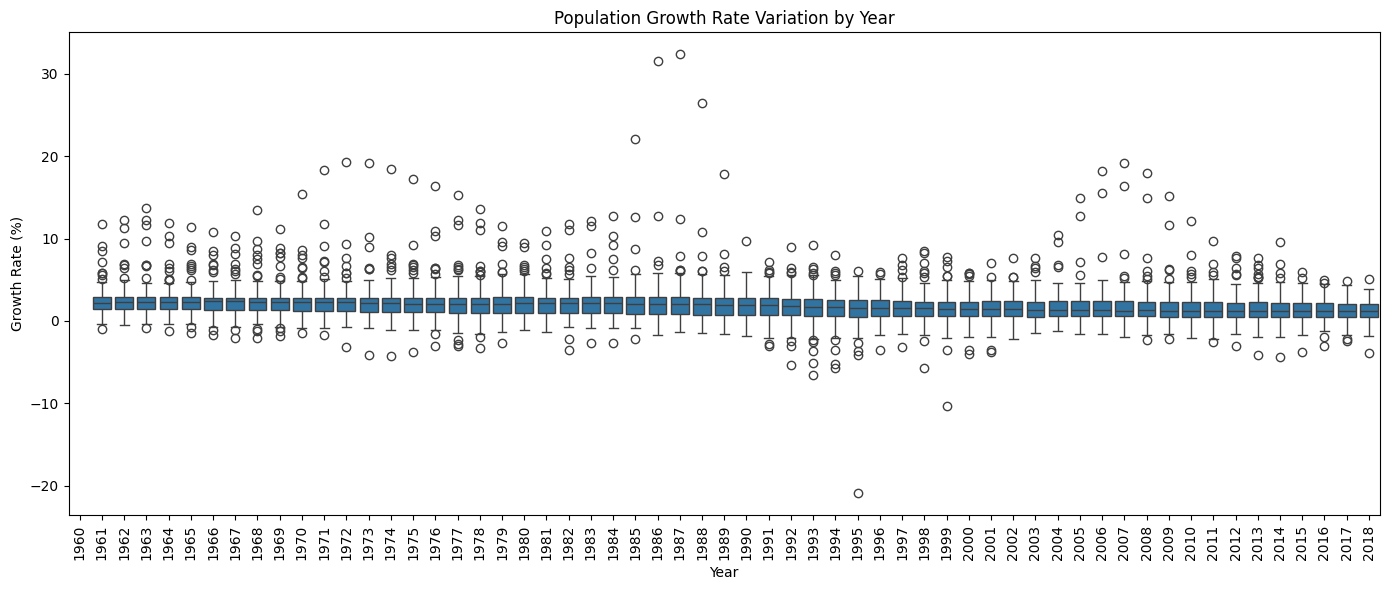

In [ ]:
if "Growth Rate (%)" in df.columns:
    df["Growth Rate (%)"] = pd.to_numeric(
        df["Growth Rate (%)"], errors="coerce"
    )

    plt.figure(figsize=(14, 6))

    sns.boxplot(
        data=df,
        x="Year",
        y="Growth Rate (%)"
    )

    plt.title("Population Growth Rate Variation by Year")
    plt.xlabel("Year")
    plt.ylabel("Growth Rate (%)")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

Feature Engineering and Selection

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X = df[["Country", "Year"]]
y = df["Population"]

preprocessor = ColumnTransformer(
    transformers=[
        ("country", OneHotEncoder(handle_unknown="ignore"),
         ["Country"]),
        ("year", StandardScaler(), ["Year"])
    ]
)

In [ ]:
# Model Selection
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    # Model 3: Decision Tree
    "Decision Tree": DecisionTreeRegressor(
        max_depth=15,
        random_state=42
    ),

    # Model 5: K-Nearest Neighbors
    "KNN": KNeighborsRegressor(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    )
}

Model Training

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Split data chronologically
split_year = int(df["Year"].quantile(0.80))

train = df[df["Year"] <= split_year]
test = df[df["Year"] > split_year]

X_train = train[["Country", "Year"]]
y_train = train["Population"]

X_test = test[["Country", "Year"]]
y_test = test["Population"]

# Re-define preprocessor to make this cell self-contained
preprocessor = ColumnTransformer(
    transformers=[
        ("country", OneHotEncoder(handle_unknown="ignore"), ["Country"]),
        ("year", StandardScaler(), ["Year"])
    ]
)

results = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results[name] = {
        "pipeline": pipeline,
        "predictions": predictions
    }

    print(name, "training completed")

Linear Regression training completed
Random Forest training completed
Decision Tree training completed
KNN training completed


Model Evaluation and Tuning

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

for name, result in results.items():

    predictions = result["predictions"]

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    print("\nModel:", name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


Model: Linear Regression
MAE: 155777495.70192596
RMSE: 322391840.45729977
R2 Score: 0.8757031497284627

Model: Random Forest
MAE: 23446721.566261258
RMSE: 85147718.53880575
R2 Score: 0.991329621189161


Model Comparison

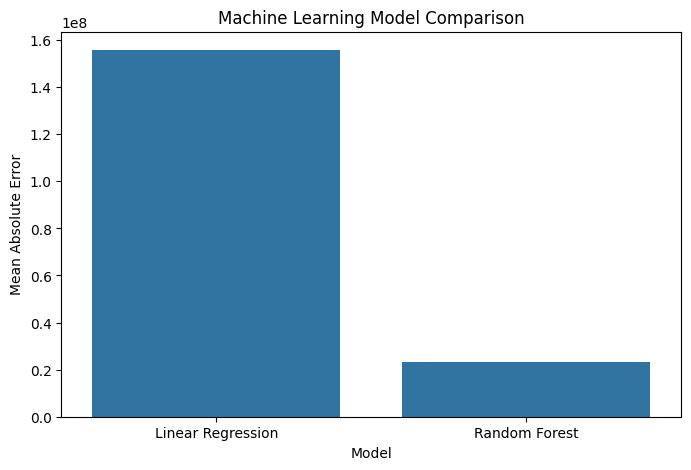

In [ ]:
model_names = []
mae_values = []

for name, result in results.items():

    model_names.append(name)

    mae = mean_absolute_error(
        y_test,
        result["predictions"]
    )

    mae_values.append(mae)

plt.figure(figsize=(8, 5))

sns.barplot(x=model_names, y=mae_values)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")
plt.show()

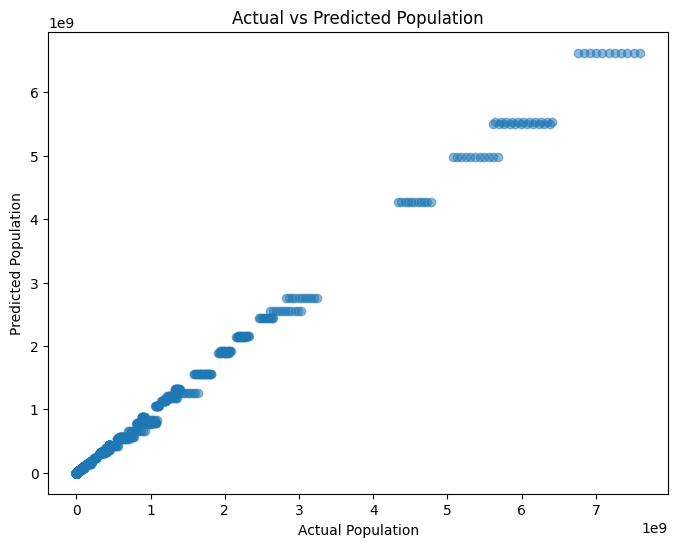

In [ ]:
best_model_name = min(
    results,
    key=lambda name: mean_absolute_error(
        y_test,
        results[name]["predictions"]
    )
)

best_model = results[best_model_name]["pipeline"]

predictions = results[best_model_name]["predictions"]

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.5)

plt.title("Actual vs Predicted Population")
plt.xlabel("Actual Population")
plt.ylabel("Predicted Population")
plt.show()

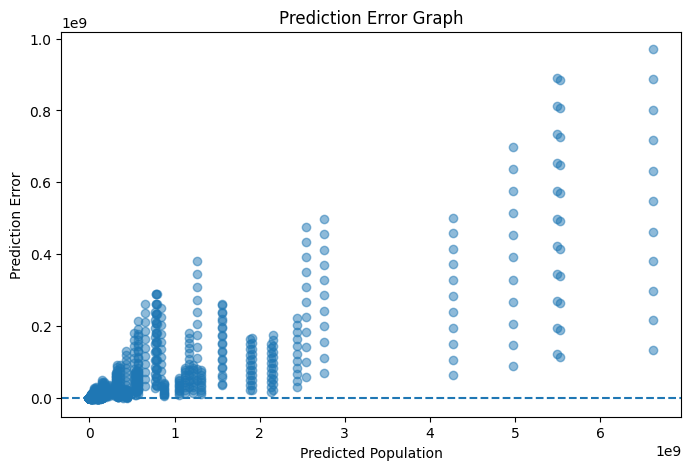

In [ ]:
errors = y_test.to_numpy() - predictions

plt.figure(figsize=(8, 5))

plt.scatter(predictions, errors, alpha=0.5)

plt.axhline(y=0, linestyle="--")

plt.title("Prediction Error Graph")
plt.xlabel("Predicted Population")
plt.ylabel("Prediction Error")
plt.show()

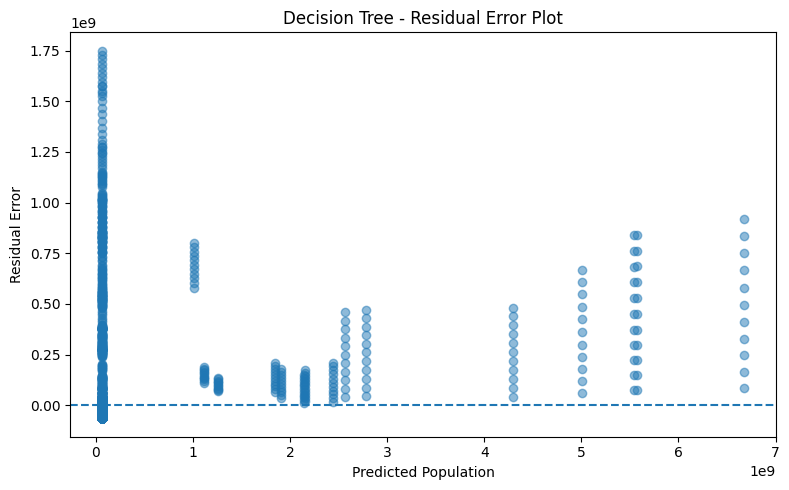

In [ ]:
import matplotlib.pyplot as plt

# Decision Tree predictions
dt_predictions = results["Decision Tree"]["predictions"]

# Calculate residual errors
dt_residuals = y_test - dt_predictions

plt.figure(figsize=(8, 5))
plt.scatter(dt_predictions, dt_residuals, alpha=0.5)

plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Population")
plt.ylabel("Residual Error")
plt.title("Decision Tree - Residual Error Plot")

plt.tight_layout()
plt.show()

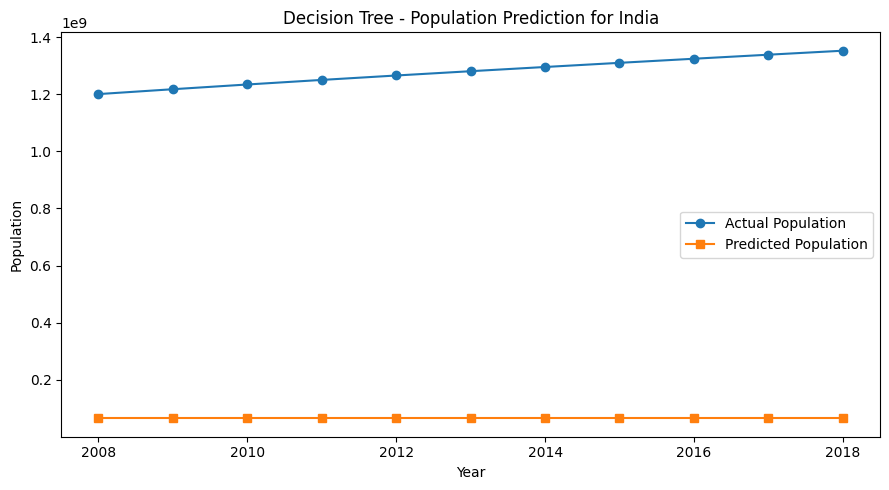

In [ ]:
dt_plot = test[["Country", "Year"]].copy()
dt_plot["Actual Population"] = y_test.values
dt_plot["Predicted Population"] = results["Decision Tree"]["predictions"]

# Select India only
country_data = dt_plot[dt_plot["Country"].str.strip().str.lower() == "india"]
country_data = country_data.sort_values("Year")

if country_data.empty:
    print("India is not available in the test dataset.")
else:
    plt.figure(figsize=(9, 5))

    plt.plot(
        country_data["Year"],
        country_data["Actual Population"],
        marker="o",
        label="Actual Population"
    )

    plt.plot(
        country_data["Year"],
        country_data["Predicted Population"],
        marker="s",
        label="Predicted Population"
    )

    plt.xlabel("Year")
    plt.ylabel("Population")
    plt.title("Decision Tree - Population Prediction for India")
    plt.legend()
    plt.tight_layout()
    plt.show()

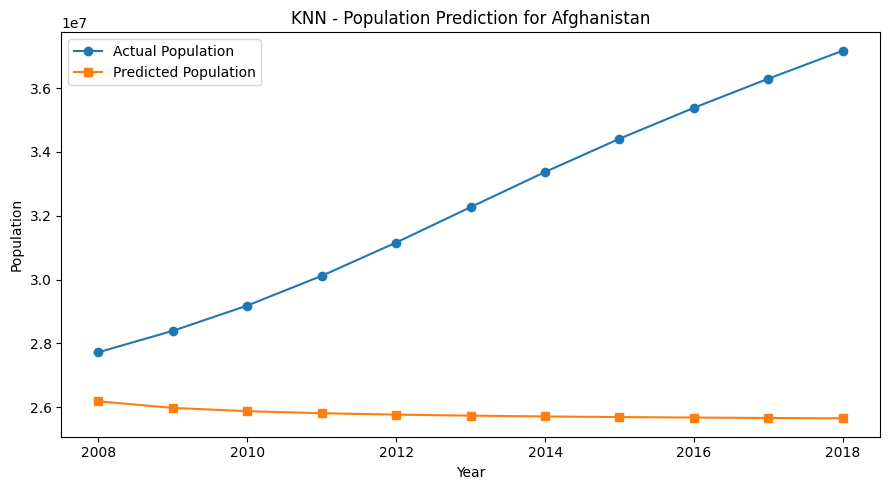

In [ ]:
knn_plot = test[["Country", "Year"]].copy()
knn_plot["Actual Population"] = y_test.values
knn_plot["Predicted Population"] = results["KNN"]["predictions"]

country_name = knn_plot["Country"].iloc[0]
country_data = knn_plot[knn_plot["Country"] == country_name].sort_values("Year")

plt.figure(figsize=(9, 5))
plt.plot(country_data["Year"], country_data["Actual Population"],
         marker="o", label="Actual Population")
plt.plot(country_data["Year"], country_data["Predicted Population"],
         marker="s", label="Predicted Population")

plt.xlabel("Year")
plt.ylabel("Population")
plt.title(f"KNN - Population Prediction for {country_name}")
plt.legend()
plt.tight_layout()
plt.show()

Model Development


In [ ]:
import os
import joblib

os.makedirs("population_ml_outputs", exist_ok=True)

joblib.dump(
    best_model,
    "population_ml_outputs/population_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
new_data = pd.DataFrame({
    "Country": ["India"],
    "Year": [2030]
})

prediction = best_model.predict(new_data)

print(
    "Predicted population of India in 2030:",
    round(prediction[0])
)

Predicted population of India in 2030: 1171092223


Model Monitoring and Maintenance

In [ ]:
monitoring = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [
        mean_absolute_error(y_test, predictions),
        np.sqrt(mean_squared_error(y_test, predictions)),
        r2_score(y_test, predictions)
    ]
})

monitoring.to_csv(
    "population_ml_outputs/monitoring_metrics.csv",
    index=False
)

print(monitoring)
print("Model monitoring completed!")

     Metric         Value
0       MAE  2.344672e+07
1      RMSE  8.514772e+07
2  R2 Score  9.913296e-01
Model monitoring completed!
